**Smart Traffic Monitoring and Lane Detection**

In [1]:
!pip install opencv-python

Saving traffic.jpg to traffic (3).jpg


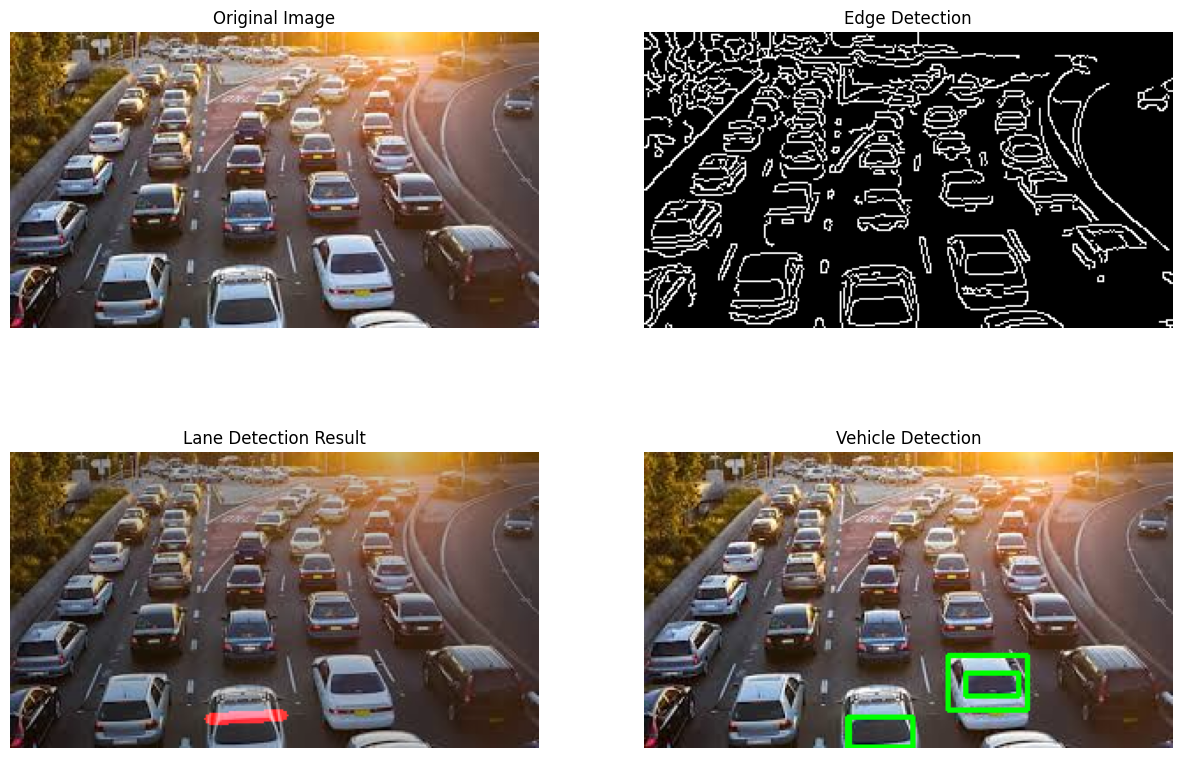

Estimated Vehicle Count: 4


In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload image
uploaded = files.upload()

# Read image
image = cv2.imread("traffic.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Gaussian Blur
blur = cv2.GaussianBlur(gray,(5,5),0)

# Edge Detection
edges = cv2.Canny(blur,50,150)

# Region of Interest
height, width = edges.shape

polygon = np.array([
[(0,height),(width,height),(width//2,height//2)]
])

mask = np.zeros_like(edges)
cv2.fillPoly(mask,polygon,255)

roi = cv2.bitwise_and(edges,mask)

# Hough Transform for Lane Detection
lines = cv2.HoughLinesP(
    roi,
    2,
    np.pi/180,
    threshold=100,
    minLineLength=40,
    maxLineGap=5
)

lane_image = np.zeros_like(image)

if lines is not None:
    for line in lines:
        x1,y1,x2,y2 = line.reshape(4)
        cv2.line(lane_image,(x1,y1),(x2,y2),(255,0,0),5)

lane_result = cv2.addWeighted(image,0.8,lane_image,1,1)

# Vehicle Detection using Contours
vehicle_count = 0

vehicle_image = image.copy()

contours,_ = cv2.findContours(edges,cv2.RETR_TREE,cv2.CHAIN_APPROX_SIMPLE)

for cnt in contours:

    area = cv2.contourArea(cnt)

    if 200 < area < 2000:

        x,y,w,h = cv2.boundingRect(cnt)

        cv2.rectangle(vehicle_image,(x,y),(x+w,y+h),(0,255,0),2)

        vehicle_count +=1

# Display Results
plt.figure(figsize=(15,10))

plt.subplot(2,2,1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(edges,cmap="gray")
plt.title("Edge Detection")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(lane_result)
plt.title("Lane Detection Result")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(vehicle_image)
plt.title("Vehicle Detection")
plt.axis("off")

plt.show()

print("Estimated Vehicle Count:",vehicle_count)

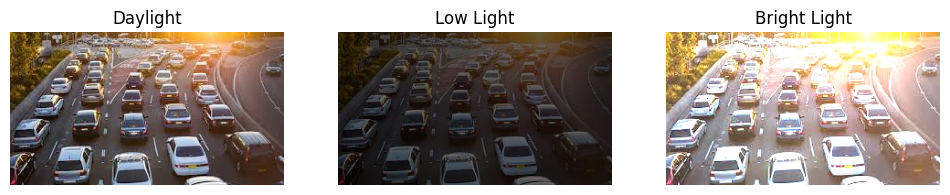

In [6]:
# Simulate lighting conditions

daylight = image.copy()

low_light = cv2.convertScaleAbs(image, alpha=0.4, beta=0)   # darker image

bright_light = cv2.convertScaleAbs(image, alpha=1.5, beta=50)  # very bright

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(daylight)
plt.title("Daylight")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(low_light)
plt.title("Low Light")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(bright_light)
plt.title("Bright Light")
plt.axis("off")

plt.show()

Saving night traffic.jpg to night traffic (1).jpg


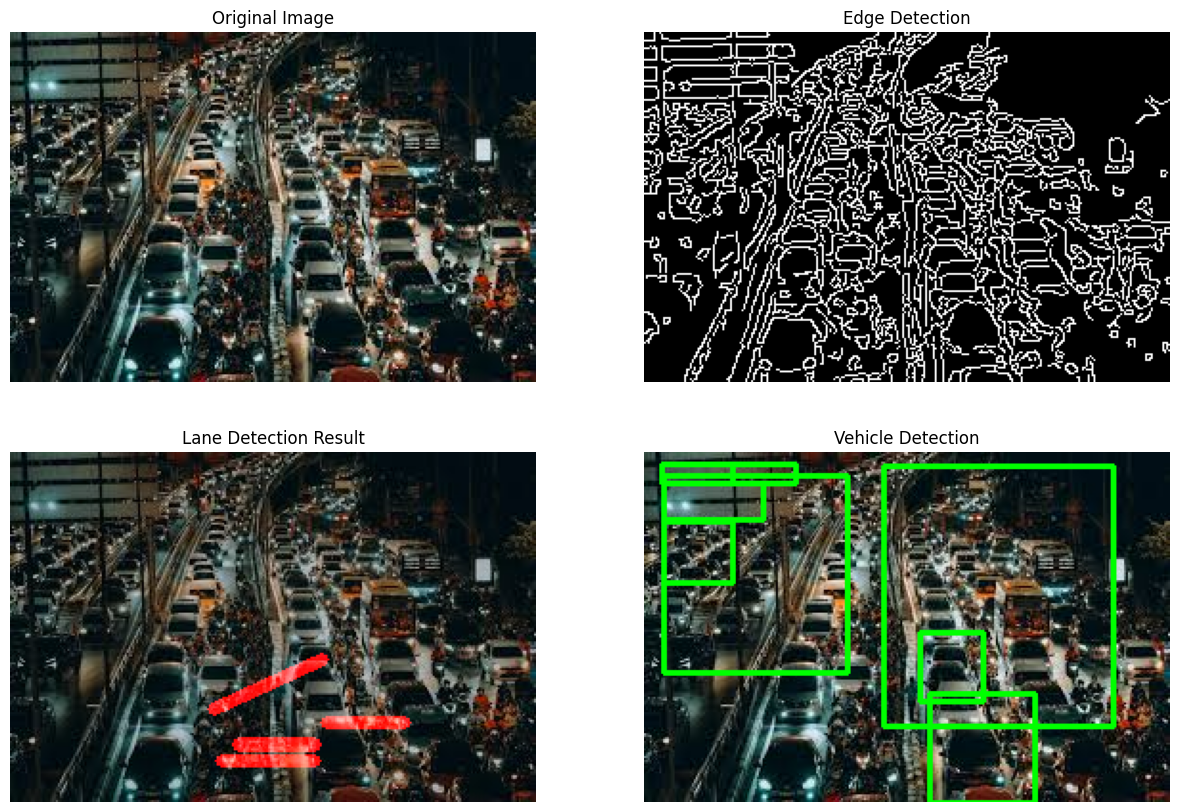

Estimated Vehicle Count: 8


In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload image
uploaded = files.upload()

# Read image
image = cv2.imread("night traffic.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Gaussian Blur
blur = cv2.GaussianBlur(gray,(5,5),0)

# Edge Detection
edges = cv2.Canny(blur,50,150)

# Region of Interest
height, width = edges.shape

polygon = np.array([
[(0,height),(width,height),(width//2,height//2)]
])

mask = np.zeros_like(edges)
cv2.fillPoly(mask,polygon,255)

roi = cv2.bitwise_and(edges,mask)

# Hough Transform for Lane Detection
lines = cv2.HoughLinesP(
    roi,
    2,
    np.pi/180,
    threshold=100,
    minLineLength=40,
    maxLineGap=5
)

lane_image = np.zeros_like(image)

if lines is not None:
    for line in lines:
        x1,y1,x2,y2 = line.reshape(4)
        cv2.line(lane_image,(x1,y1),(x2,y2),(255,0,0),5)

lane_result = cv2.addWeighted(image,0.8,lane_image,1,1)

# Vehicle Detection using Contours
vehicle_count = 0

vehicle_image = image.copy()

contours,_ = cv2.findContours(edges,cv2.RETR_TREE,cv2.CHAIN_APPROX_SIMPLE)

for cnt in contours:

    area = cv2.contourArea(cnt)

    if 200 < area < 2000:

        x,y,w,h = cv2.boundingRect(cnt)

        cv2.rectangle(vehicle_image,(x,y),(x+w,y+h),(0,255,0),2)

        vehicle_count +=1

# Display Results
plt.figure(figsize=(15,10))

plt.subplot(2,2,1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(edges,cmap="gray")
plt.title("Edge Detection")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(lane_result)
plt.title("Lane Detection Result")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(vehicle_image)
plt.title("Vehicle Detection")
plt.axis("off")

plt.show()

print("Estimated Vehicle Count:",vehicle_count)